# Relational Model and SQL Review Studio

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lolusername/CST4714_DB_admin/blob/main/week_02/01_relational_sql_review.ipynb)

[View on GitHub](https://github.com/lolusername/CST4714_DB_admin/blob/main/week_02/01_relational_sql_review.ipynb)

**Language and environment:** Python 3 runs SQL through DuckDB in Colab or
local Jupyter. No database account is required.

Click **Open in Colab** to open this notebook directly. Save a copy in Drive,
then run the cells in order. Before either lab, run **Use the Complete Week 2 Lab Dataset**.


This notebook rebuilds the SQL ideas that later database-administration work
depends on. It is intentionally direct: each code cell runs SQL, and each
Markdown section explains what the result means.

**By the end, you will be able to:**

- translate selection, projection, join, difference, and grouping into SQL;
- state what one result row represents;
- predict where duplicate rows and `NULL` values come from;
- verify a query with a second reasoning path; and
- test a data change inside a transaction without keeping it.

The data is synthetic. No database account, database password, or remote database connection is required.

## Run order and submission

Run numbered cells in order and stop at each student workspace. The cell title is the number used in the teaching guide. Collapsed setup still runs; expand it to inspect the implementation.

| Cell | What you do |
|---|---|
| 01 | Install DuckDB (body collapsed) |
| 02 | Open the temporary local database (body collapsed) |
| 03 | Load the small 4 / 6 / 9 fixture (body collapsed) |
| 04 | Check the small-fixture counts |
| 05 | Filter high-priority tickets |
| 06 | Edit the active and priority predicates |
| 07 | Compare projection with DISTINCT |
| 08 | Find NULL assignees |
| 09 | Join tickets to requesters |
| 10 | Preserve tickets with a LEFT JOIN |
| 11 | Inspect the three events of one ticket |
| 12 | Group tickets by category |
| 13 | Combine result sets with UNION |
| 14 | Compare result sets with EXCEPT |
| 15 | Count active work per staff member |
| 16 | Rehearse an update and roll it back |
| 17 | Load the complete 8 / 12 / 21 lab fixture (body collapsed) |

**Required hand-ins:** Day 1: `week_02_sql_review.sql`; Day 2: `week_02_relational_sql_studio.sql`. Use this notebook as a workspace; submit the named SQL file with comments in Brightspace. No separate notebook submission is required.


## The first Week 2 examples: a separate small database

The unqualified `users`, `tickets`, and `ticket_events` tables in the notebook's
`main` schema hold 4 users, 6 tickets, and 9 events. They are a separate teaching
fixture; they do not have every column or every enforced rule of Metro Support.

| Table | Complete columns, types, and meaning |
|---|---|
| users | `user_id INTEGER` primary key; `display_name VARCHAR` person label; `role VARCHAR` resident or agent; `neighborhood VARCHAR` Harbor, Northside, or Central. Every field is required. |
| tickets | `ticket_id INTEGER` primary key; `requester_id INTEGER` requesting person; nullable `assignee_id INTEGER` assigned person; `category VARCHAR` parks/sanitation/streetlight/water; `priority VARCHAR` low/medium/high/urgent; `status VARCHAR` new/open/in_progress/resolved; `subject VARCHAR` description; `opened_at TIMESTAMP` recorded time. All except assignee are required. |
| ticket_events | `event_id INTEGER` primary key; `ticket_id INTEGER` related request; `actor_id INTEGER` person acting; `event_type VARCHAR` created/assigned/status_changed; `event_at TIMESTAMP` recorded event time. Every field is required. |

The small fixture uses these ID relationships in its data but does not declare
foreign keys or allowed-value CHECKs. The full lab fixture does declare foreign
keys. Its timestamps include time-zone metadata; these small-example timestamps
do not. SQL NULL still means missing or inapplicable, never a string.

Complete example rows, in the column order above:

```text
users: (101, 'Requester 101', 'resident', 'Harbor')
tickets: (1001, 101, 201, 'streetlight', 'high', 'open',
          'Streetlight dark near bus stop', '2026-02-01 23:10:00')
ticket_events: (5001, 1001, 101, 'created', '2026-02-01 23:10:00')
```

Read these first; switch to the full fixture reference before either lab.


## Data reference before the first query

**Two different fixtures:** worked examples use unqualified tables in `main` (4 users / 6 tickets / 9 events). Labs use explicitly qualified `metro_support` tables (8 / 12 / 21). The small fixture omits email, created_at, closed_at, old_status, new_status, and note. Its opening times are plain TIMESTAMP values, without time-zone metadata. Run the visible small-fixture count check, then the named full-fixture setup before either lab. The reference below describes the complete lab fixture.

### Complete Metro Support fixture

Metro Support is a fictional help desk. All people and records are synthetic.
The complete lab fixture contains **8 users, 12 tickets, and 21 events**. A user
may request many tickets; a ticket may have one assignee or no assignee; a ticket
may have many history events. Requester, assignee, and actor refer to different
roles and all point to `users.user_id`.

These are the fixture's observed values, not all database-enforced rules. The
baseline SQL declares keys, required fields, unique email, and the date-order
check. It does **not** yet declare allowed-value CHECK constraints for status,
priority, category, or role. The integrity lab adds some of those rules.

Every row has the declared columns. SQL NULL is a value marker for missing or
inapplicable information, not an absent column, zero, or the text 'NULL'. Empty
CSV fields in this fixture load as SQL NULL. The SQL uses explicit integer IDs;
the identity experiment later creates a separate generated `note_id`.

### users

One row represents one person.

| Field | Type and rule | Meaning |
|---|---|---|
| `user_id` | integer; primary key | Unique person identifier; supplied explicitly in this fixture |
| `display_name` | text; required | Synthetic display label; it is not a stable join key |
| `email` | text; required and unique | Synthetic contact address ending in example.test |
| `role` | text; required | Observed: resident, agent, supervisor, analyst |
| `neighborhood` | text; required | Observed: Harbor, Northside, Central |
| `created_at` | timestamp with time zone; required | When the user record was created |

One complete example record (JSON notation for readability; SQL uses typed columns):

```json
{
  "user_id": 101,
  "display_name": "Requester 101",
  "email": "requester101@example.test",
  "role": "resident",
  "neighborhood": "Harbor",
  "created_at": "2026-01-08T14:20:00Z"
}
```

### tickets

One row represents one request.

| Field | Type and rule | Meaning |
|---|---|---|
| `ticket_id` | integer; primary key | One stable identifier for one request |
| `requester_id` | integer; required foreign key | Person who reported the request; references users.user_id |
| `assignee_id` | integer; nullable foreign key | Staff member assigned to the request; NULL means unassigned |
| `category` | text; required | Observed: parks, sanitation, streetlight, transportation, water |
| `priority` | text; required | Observed: low, medium, high, urgent |
| `status` | text; required | Observed: new, open, in_progress, resolved, closed |
| `subject` | text; required | Short description of the request |
| `opened_at` | timestamp with time zone; required | When the request was recorded |
| `closed_at` | timestamp with time zone; nullable | Closure time if recorded; NULL is not a date |

One complete example record (JSON notation for readability; SQL uses typed columns):

```json
{
  "ticket_id": 1001,
  "requester_id": 101,
  "assignee_id": 201,
  "category": "streetlight",
  "priority": "high",
  "status": "open",
  "subject": "Streetlight dark near bus stop",
  "opened_at": "2026-02-01T23:10:00Z",
  "closed_at": null
}
```

### ticket_events

One row represents one event on one request.

| Field | Type and rule | Meaning |
|---|---|---|
| `event_id` | integer; primary key | One stable identifier for one history event |
| `ticket_id` | integer; required foreign key | Request this event describes; references tickets.ticket_id |
| `actor_id` | integer; required foreign key | Person who acted; references users.user_id |
| `event_type` | text; required | Observed: created, assigned, status_changed |
| `old_status` | text; nullable | Prior status when relevant; absent for a creation event |
| `new_status` | text; nullable | Recorded resulting status when relevant |
| `note` | text; nullable | Explanation attached to the event |
| `event_at` | timestamp with time zone; required | When the event was recorded |

One complete example record (JSON notation for readability; SQL uses typed columns):

```json
{
  "event_id": 5001,
  "ticket_id": 1001,
  "actor_id": 101,
  "event_type": "created",
  "old_status": null,
  "new_status": "open",
  "note": "Reported through mobile form",
  "event_at": "2026-02-01T23:10:00Z"
}
```

### Names that change between exercises

- Week 1 uses a four-ticket extract and a two-row `agents` table. Its `agent_id`
  corresponds to the later `users.user_id`; its `name` corresponds to `display_name`.
- The first Week 2 examples use a smaller **4 / 6 / 9** fixture in `main`, with
  fewer columns. The separate **8 / 12 / 21** lab fixture uses `metro_support`.
  They are different instances; do not transfer requester IDs or counts between them.
- Week 5's `lock_lab.tickets` intentionally has only `ticket_id`, `priority`,
  and `status`. Its complete starting row is **1004 / medium / open**. The main
  Metro Support row 1004 is **low / new**. Always name the schema when explaining it.
- In the full fixture, active means `new`, `open`, or `in_progress`. Week 1's
  smaller question defines active as only `new` or `open`.

The original CSV files retain every record. The notebook also provides a named
fixture-loading cell and a visible count check before the lab queries.


## Worked still diagram

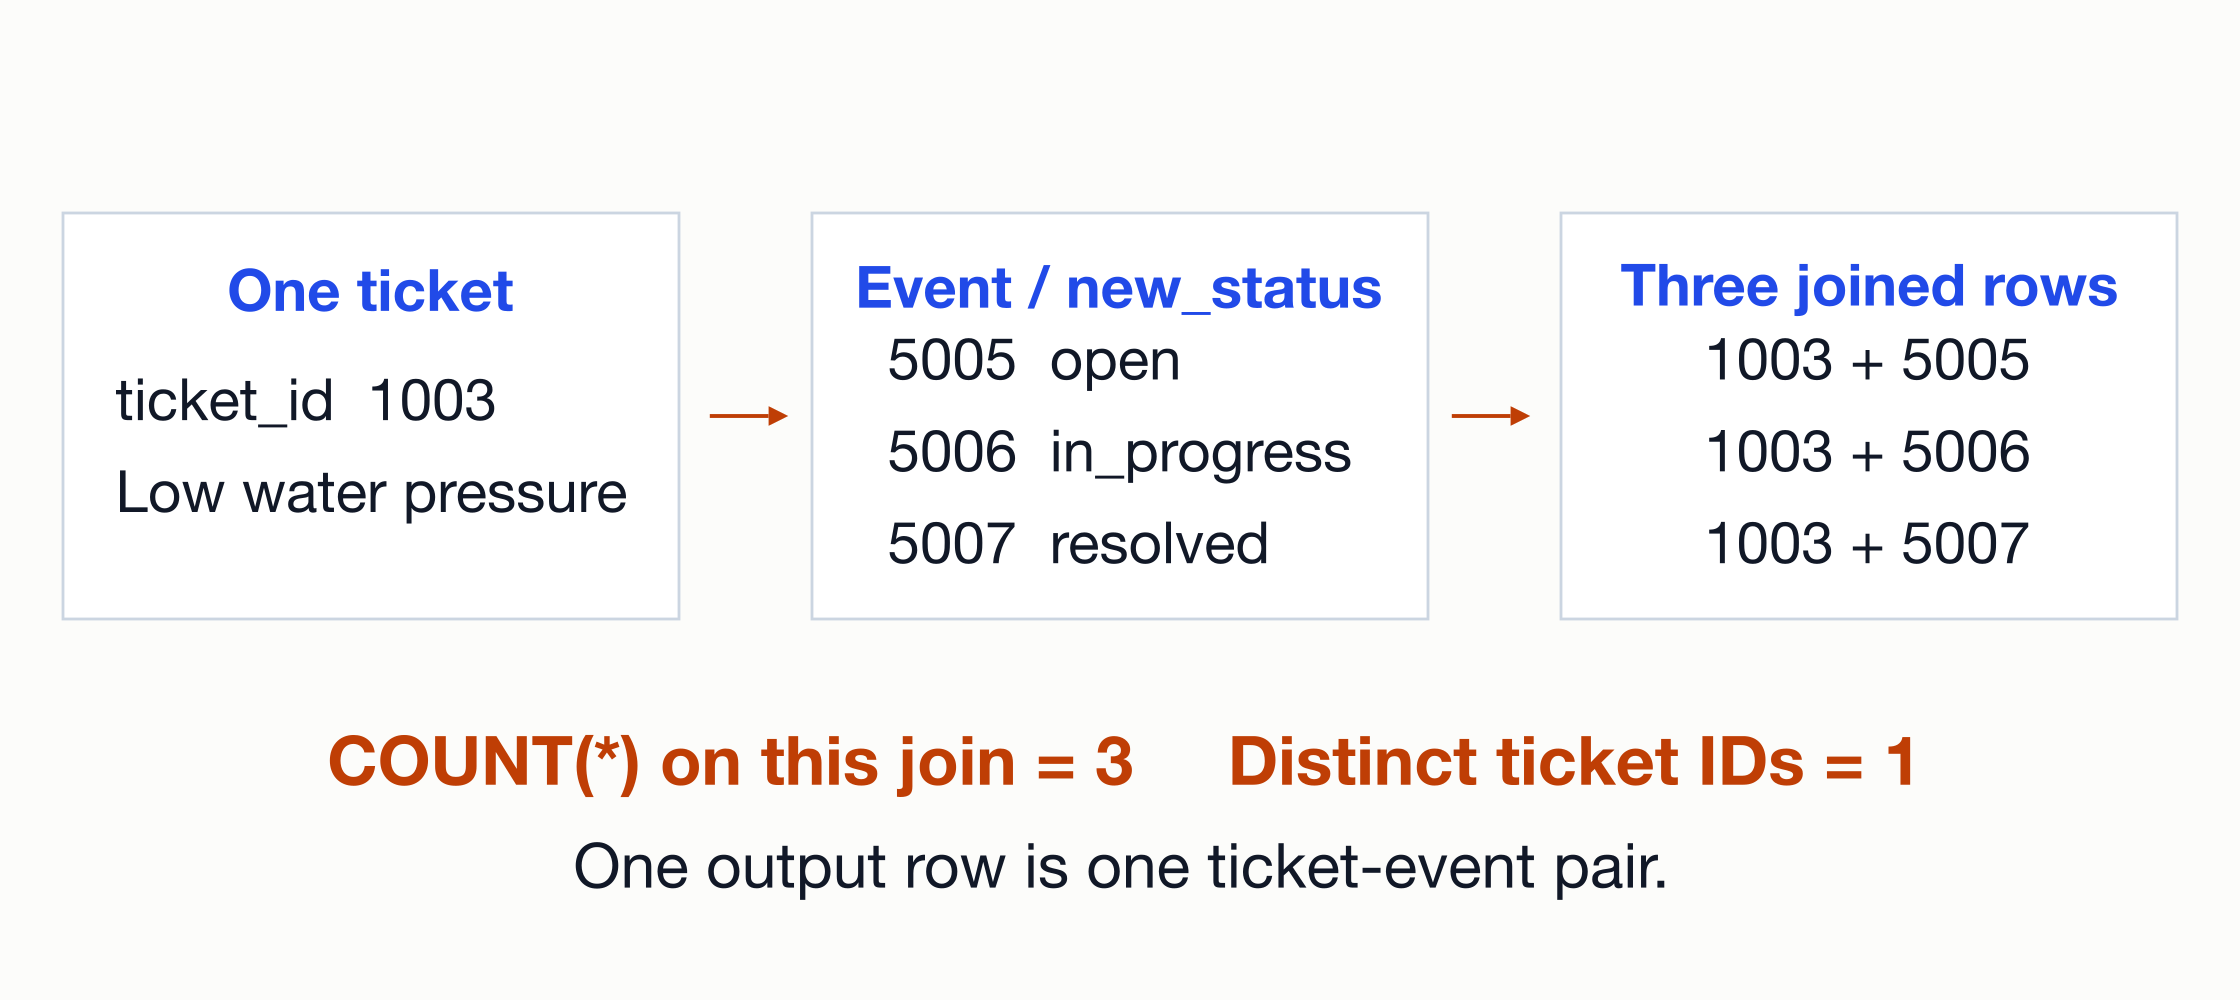

Ticket 1003 joins to events 5005, 5006, and 5007, with new statuses open, in_progress, and resolved. Three joined rows represent three ticket-event pairs but only one distinct ticket.

This diagram uses the complete 8 / 12 / 21 lab fixture, not the small first-example fixture.


## How to Use This Notebook

Run cells from top to bottom. Before each query cell, read the prediction prompt
and say what you expect. After the result appears, compare it with your prediction.

We use DuckDB because it runs a relational SQL engine inside the notebook. The
course's cloud database is PostgreSQL, so some administrative syntax will differ,
but the relational reasoning and review queries here transfer directly.

In [ ]:
#@title Cell 01 · Install DuckDB
# Install DuckDB in the notebook runtime. This does not create an online account.
%pip -q install duckdb

In [ ]:
#@title Cell 02 · Open the temporary local database
import duckdb

# This database exists only in the notebook session. Closing the runtime removes it.
con = duckdb.connect()
print("DuckDB is ready:", duckdb.__version__)

## 1. Create a Small Relational Instance

A **relation schema** names the attributes and their domains. A **relation
instance** is the current set of tuples. In SQL, we define tables and then insert
rows.

The setup cell is longer than later cells because it creates all three relations.
You do not need to memorize it. Notice the primary keys and the identifiers that
connect tickets to users and events to tickets.

In [ ]:
#@title Cell 03 · Load the small 4 / 6 / 9 fixture
con.execute('''
CREATE TABLE users (
    user_id INTEGER PRIMARY KEY,
    display_name VARCHAR NOT NULL,
    role VARCHAR NOT NULL,
    neighborhood VARCHAR NOT NULL
);

CREATE TABLE tickets (
    ticket_id INTEGER PRIMARY KEY,
    requester_id INTEGER NOT NULL,
    assignee_id INTEGER,
    category VARCHAR NOT NULL,
    priority VARCHAR NOT NULL,
    status VARCHAR NOT NULL,
    subject VARCHAR NOT NULL,
    opened_at TIMESTAMP NOT NULL
);

CREATE TABLE ticket_events (
    event_id INTEGER PRIMARY KEY,
    ticket_id INTEGER NOT NULL,
    actor_id INTEGER NOT NULL,
    event_type VARCHAR NOT NULL,
    event_at TIMESTAMP NOT NULL
);

INSERT INTO users VALUES
    (101, 'Requester 101', 'resident', 'Harbor'),
    (102, 'Requester 102', 'resident', 'Northside'),
    (201, 'Agent 201', 'agent', 'Central'),
    (202, 'Agent 202', 'agent', 'Northside');

INSERT INTO tickets VALUES
    (1001, 101, 201, 'streetlight', 'high', 'open',
     'Streetlight dark near bus stop', '2026-02-01 23:10:00'),
    (1002, 102, 202, 'sanitation', 'medium', 'in_progress',
     'Missed recycling pickup', '2026-02-02 15:45:00'),
    (1003, 101, 201, 'water', 'urgent', 'resolved',
     'Low water pressure', '2026-02-03 12:05:00'),
    (1004, 102, NULL, 'parks', 'low', 'new',
     'Broken bench slat', '2026-02-04 17:20:00'),
    (1005, 101, 202, 'sanitation', 'high', 'resolved',
     'Overflowing corner bin', '2026-02-05 14:00:00'),
    (1006, 102, 201, 'streetlight', 'medium', 'in_progress',
     'Flickering lamp outside library', '2026-02-06 01:30:00');

INSERT INTO ticket_events VALUES
    (5001, 1001, 101, 'created', '2026-02-01 23:10:00'),
    (5002, 1001, 201, 'assigned', '2026-02-02 14:05:00'),
    (5003, 1002, 102, 'created', '2026-02-02 15:45:00'),
    (5004, 1002, 202, 'status_changed', '2026-02-03 13:30:00'),
    (5005, 1003, 101, 'created', '2026-02-03 12:05:00'),
    (5006, 1003, 201, 'status_changed', '2026-02-03 14:25:00'),
    (5007, 1003, 201, 'status_changed', '2026-02-03 19:40:00'),
    (5008, 1004, 102, 'created', '2026-02-04 17:20:00'),
    (5009, 1005, 202, 'status_changed', '2026-02-05 20:15:00');
''')

print("Created users, tickets, and ticket_events.")

### Verify Before Querying

Expected counts come from the setup: 4 users, 6 tickets, and 9 events. A count
check confirms how many rows loaded; inspecting identifiers and values answers
different questions.

In [ ]:
#@title Cell 04 · Check the small-fixture counts
con.sql('''
SELECT 'users' AS relation_name, count(*) AS row_count FROM users
UNION ALL
SELECT 'tickets', count(*) FROM tickets
UNION ALL
SELECT 'ticket_events', count(*) FROM ticket_events
ORDER BY relation_name;
''').show()

## 2. Selection Keeps Rows; Projection Keeps Attributes

Relational-algebra reasoning:

```text
pi ticket_id, subject, priority (
  sigma priority = 'high' (tickets)
)
```

SQL writes projection in `SELECT` and selection in `WHERE`. Before running the
next cell, predict the number of rows and the three output attributes.

In [ ]:
#@title Cell 05 · Filter high-priority tickets
con.sql('''
SELECT ticket_id, subject, priority
FROM tickets
WHERE priority = 'high'
ORDER BY ticket_id;
''').show()

### Your Turn: Change One Predicate

Run the starter query. Then change it so the result contains active tickets with
either `medium` or `high` priority. In this course, active means `new`, `open`, or
`in_progress`. Predict the result grain before you edit.

In [ ]:
#@title Cell 06 · Edit the active and priority predicates
# Grain: one row per ticket.
# Edit the predicates, run the query, and compare with your prediction.
con.sql('''
SELECT ticket_id, priority, status, subject
FROM tickets
WHERE status IN ('open', 'in_progress')
  AND priority IN ('medium', 'high')
ORDER BY opened_at;
''').show()

## 3. SQL Usually Preserves Duplicates

Classical relational algebra uses sets. SQL query results usually use bag
semantics. Agent 201 is assigned to three tickets, so projecting only `assignee_id`
can repeat her identifier.

In [ ]:
#@title Cell 07 · Compare projection with DISTINCT
print("Ordinary projection:")
con.sql("SELECT assignee_id FROM tickets ORDER BY assignee_id;").show()

print("Projection with duplicate removal:")
con.sql("SELECT DISTINCT assignee_id FROM tickets ORDER BY assignee_id;").show()

`DISTINCT` is correct only when the question asks for unique values. It should not
be used to hide rows created by an incorrect join.

Also notice the missing assignee. `NULL` is not zero or an empty string. Test it
with `IS NULL`, not `= NULL`.

In [ ]:
#@title Cell 08 · Find NULL assignees
con.sql('''
SELECT ticket_id, subject
FROM tickets
WHERE assignee_id IS NULL;
''').show()

## 4. A Join Pairs Related Tuples

A Cartesian product of 6 tickets and 4 users contains 24 pairs. The join condition
keeps pairs where `tickets.assignee_id = users.user_id`.

Predict why the result below has five rows rather than six.

In [ ]:
#@title Cell 09 · Join tickets to requesters
con.sql('''
SELECT
    t.ticket_id,
    t.subject,
    u.display_name AS assignee_name
FROM tickets AS t
JOIN users AS u
    ON u.user_id = t.assignee_id
ORDER BY t.ticket_id;
''').show()

An inner join removes ticket 1004 because its assignee is unknown. If the question
requires every ticket, use a left join. The left-side ticket remains and the
right-side attributes become `NULL` when no match exists.

In [ ]:
#@title Cell 10 · Preserve tickets with a LEFT JOIN
con.sql('''
SELECT
    t.ticket_id,
    t.subject,
    u.display_name AS assignee_name
FROM tickets AS t
LEFT JOIN users AS u
    ON u.user_id = t.assignee_id
ORDER BY t.ticket_id;
''').show()

## 5. One-to-Many Joins Change the Grain

A ticket can have many events. The next result is one row per event, not one row
per ticket. Predict how many rows ticket 1003 will produce, then run the query.

In [ ]:
#@title Cell 11 · Inspect the three events of one ticket
con.sql('''
SELECT t.ticket_id, t.subject, e.event_id, e.event_type, e.event_at
FROM tickets AS t
JOIN ticket_events AS e
    ON e.ticket_id = t.ticket_id
WHERE t.ticket_id = 1003
ORDER BY e.event_at;
''').show()

Three rows are correct because the result grain is one event. If a report needs
one row per ticket, aggregate the events or choose one event intentionally. Do not
add `DISTINCT` until you understand the grain.

## 6. Grouping Changes the Grain

The next result is one row per category. `count(*)` counts tickets in each group.
Conditional aggregation counts only tickets whose status is unresolved.

In [ ]:
#@title Cell 12 · Group tickets by category
con.sql('''
SELECT
    category,
    count(*) AS ticket_count,
    count(*) FILTER (
        WHERE status IN ('new', 'open', 'in_progress')
    ) AS unresolved_count,
    max(opened_at) AS latest_opened_at
FROM tickets
GROUP BY category
ORDER BY unresolved_count DESC, category;
''').show()

### Verify a Group Independently

The grouped query is compact, so verify one category with a simpler filtered
query. This is a different reasoning path, not the same query copied twice.

In [ ]:
#@title Cell 13 · Combine result sets with UNION
con.sql('''
SELECT ticket_id, status
FROM tickets
WHERE category = 'streetlight'
ORDER BY ticket_id;
''').show()

## 7. Difference Answers "In the First, Not the Second"

`EXCEPT` is SQL's set-difference operator. The next question asks for users who
appear as requesters but not as assignees.

In [ ]:
#@title Cell 14 · Compare result sets with EXCEPT
con.sql('''
SELECT requester_id AS user_id
FROM tickets
EXCEPT
SELECT assignee_id
FROM tickets
WHERE assignee_id IS NOT NULL
ORDER BY user_id;
''').show()

## 8. A CTE Names an Intermediate Relation

Read the query from the inside out. `active_tickets` is a named intermediate
relation. The outer query joins that result to users and groups by agent.

In [ ]:
#@title Cell 15 · Count active work per staff member
con.sql('''
WITH active_tickets AS (
    SELECT ticket_id, assignee_id
    FROM tickets
    WHERE status IN ('new', 'open', 'in_progress')
)
SELECT
    u.display_name,
    count(a.ticket_id) AS active_ticket_count
FROM users AS u
LEFT JOIN active_tickets AS a
    ON a.assignee_id = u.user_id
WHERE u.role = 'agent'
GROUP BY u.user_id, u.display_name
ORDER BY active_ticket_count DESC, u.display_name;
''').show()

## 9. Preview, Change, Return, Verify, Roll Back

Before changing data, use the intended predicate in a `SELECT`. Then use a
transaction and `RETURNING`. This notebook rolls the change back, so the original
state returns.

In [ ]:
#@title Cell 16 · Rehearse an update and roll it back
print("Preview the exact target:")
con.sql('''
    SELECT ticket_id, priority
    FROM tickets
    WHERE ticket_id = 1006;
''').show()

con.execute("BEGIN")

print("Change visible inside the transaction:")
con.sql('''
    UPDATE tickets
    SET priority = 'high'
    WHERE ticket_id = 1006
    RETURNING ticket_id, priority;
''').show()

con.execute("ROLLBACK")

print("Original state restored after rollback:")
con.sql('''
    SELECT ticket_id, priority
    FROM tickets
    WHERE ticket_id = 1006;
''').show()

## 10. Explain What the Results Establish

Write short answers in a new Markdown cell or your lab file:

1. Which query changed its result grain, and what did one output row represent?
2. Why did the left join preserve a row that the inner join removed?
3. What did the independent streetlight query confirm? What remains untested?
4. Which relational-algebra operation did `EXCEPT` express?
5. Which result confirms that the priority update was rolled back?

## Readiness Check

You are ready to continue when you can predict and explain the queries, not just
run them. If one section is unclear, edit its query, use smaller projections, and
inspect one identifier at a time.

**License:** prose CC BY-NC-SA 4.0; code MIT; synthetic example data CC0.

## Use the Complete Week 2 Lab Dataset

The worked examples above deliberately used a smaller instance: 4 users, 6
tickets, and 9 events. The two Week 2 labs use **8 users, 12 tickets, and 21
events**. Run the next cell before doing either lab. It creates a separate
`metro_support` schema in this in-memory database and selects that schema.
Rerunning it resets only that practice schema.

This copy uses DuckDB's `SET schema` to choose the default namespace.
Setup names such as `metro_support.users` include the schema explicitly so
the lab's tables and foreign keys cannot refer to the smaller example tables.
The lab queries use full names such as `metro_support.tickets`.

A foreign key is a rule requiring an identifier to match a row in another
table. For this DuckDB exercise, the event-to-ticket foreign-key check is
omitted so the priority-update experiment can run. The IDs and joins stay
the same; all other constraints in this setup remain. DuckDB can reject
updates to referenced rows even when their IDs are unchanged. The PostgreSQL
setup includes the event-to-ticket constraint. We will use PostgreSQL to
study enforced relationships in Week 3. See DuckDB's
[foreign-key update limitation](https://duckdb.org/docs/current/sql/indexes#over-eager-constraint-checking-in-foreign-keys).

In [ ]:
#@title Cell 17 · Load the complete 8 / 12 / 21 lab fixture
con.execute("""
-- Metro Support DuckDB practice setup
-- Run only in a course or personal practice database. This resets the
-- metro_support schema so the dataset is reproducible.

DROP SCHEMA IF EXISTS metro_support CASCADE;
CREATE SCHEMA metro_support;
SET schema = 'metro_support';

CREATE TABLE metro_support.users (
    user_id integer PRIMARY KEY,
    display_name text NOT NULL,
    email text NOT NULL UNIQUE,
    role text NOT NULL,
    neighborhood text NOT NULL,
    created_at timestamptz NOT NULL
);

CREATE TABLE metro_support.tickets (
    ticket_id integer PRIMARY KEY,
    requester_id integer NOT NULL REFERENCES metro_support.users(user_id),
    assignee_id integer REFERENCES metro_support.users(user_id),
    category text NOT NULL,
    priority text NOT NULL,
    status text NOT NULL,
    subject text NOT NULL,
    opened_at timestamptz NOT NULL,
    closed_at timestamptz,
    CHECK (closed_at IS NULL OR closed_at >= opened_at)
);

CREATE TABLE metro_support.ticket_events (
    event_id integer PRIMARY KEY,
    ticket_id integer NOT NULL, -- Matches tickets.ticket_id; see the explanation above.
    actor_id integer NOT NULL REFERENCES metro_support.users(user_id),
    event_type text NOT NULL,
    old_status text,
    new_status text,
    note text,
    event_at timestamptz NOT NULL
);

INSERT INTO metro_support.users
    (user_id, display_name, email, role, neighborhood, created_at)
VALUES
    (101, 'Requester 101', 'requester101@example.test', 'resident', 'Harbor', '2026-01-08T14:20:00Z'),
    (102, 'Requester 102', 'requester102@example.test', 'resident', 'Northside', '2026-01-10T09:15:00Z'),
    (103, 'Requester 103', 'requester103@example.test', 'resident', 'Central', '2026-01-12T18:05:00Z'),
    (104, 'Requester 104', 'requester104@example.test', 'resident', 'Harbor', '2026-01-18T11:40:00Z'),
    (201, 'Agent 201', 'agent201@example.test', 'agent', 'Central', '2025-11-03T13:00:00Z'),
    (202, 'Agent 202', 'agent202@example.test', 'agent', 'Northside', '2025-11-05T13:00:00Z'),
    (203, 'Agent 203', 'agent203@example.test', 'supervisor', 'Central', '2025-09-14T13:00:00Z'),
    (204, 'Sam Okafor', 'sam.okafor@example.test', 'analyst', 'Harbor', '2025-12-01T13:00:00Z');

INSERT INTO metro_support.tickets
    (ticket_id, requester_id, assignee_id, category, priority, status, subject, opened_at, closed_at)
VALUES
    (1001, 101, 201, 'streetlight', 'high', 'open', 'Streetlight dark near bus stop', '2026-02-01T23:10:00Z', NULL),
    (1002, 102, 202, 'sanitation', 'medium', 'in_progress', 'Missed recycling pickup', '2026-02-02T15:45:00Z', NULL),
    (1003, 103, 201, 'water', 'urgent', 'resolved', 'Low water pressure', '2026-02-03T12:05:00Z', '2026-02-03T19:40:00Z'),
    (1004, 104, NULL, 'parks', 'low', 'new', 'Broken bench slat', '2026-02-04T17:20:00Z', NULL),
    (1005, 101, 202, 'sanitation', 'high', 'resolved', 'Overflowing corner bin', '2026-02-05T14:00:00Z', '2026-02-05T20:15:00Z'),
    (1006, 102, 201, 'streetlight', 'medium', 'in_progress', 'Flickering lamp outside library', '2026-02-06T01:30:00Z', NULL),
    (1007, 103, 202, 'parks', 'medium', 'open', 'Playground gate will not latch', '2026-02-07T16:10:00Z', NULL),
    (1008, 104, 201, 'water', 'high', 'resolved', 'Hydrant leaking slowly', '2026-02-08T10:25:00Z', '2026-02-09T09:05:00Z'),
    (1009, 101, NULL, 'transportation', 'medium', 'new', 'Bus shelter panel cracked', '2026-02-09T22:15:00Z', NULL),
    (1010, 102, 202, 'sanitation', 'low', 'closed', 'Replacement bin request', '2026-02-10T13:50:00Z', '2026-02-12T16:30:00Z'),
    (1011, 103, 201, 'transportation', 'high', 'open', 'Crosswalk signal delayed', '2026-02-11T08:35:00Z', NULL),
    (1012, 104, 202, 'streetlight', 'low', 'resolved', 'Lamp stays on during daytime', '2026-02-12T14:45:00Z', '2026-02-14T18:10:00Z');

INSERT INTO metro_support.ticket_events
    (event_id, ticket_id, actor_id, event_type, old_status, new_status, note, event_at)
VALUES
    (5001, 1001, 101, 'created', NULL, 'open', 'Reported through mobile form', '2026-02-01T23:10:00Z'),
    (5002, 1001, 201, 'assigned', 'open', 'open', 'Electrical crew notified', '2026-02-02T14:05:00Z'),
    (5003, 1002, 102, 'created', NULL, 'open', 'Pickup was scheduled for Monday', '2026-02-02T15:45:00Z'),
    (5004, 1002, 202, 'status_changed', 'open', 'in_progress', 'Route supervisor checking vehicle log', '2026-02-03T13:30:00Z'),
    (5005, 1003, 103, 'created', NULL, 'open', 'Pressure lower on two floors', '2026-02-03T12:05:00Z'),
    (5006, 1003, 201, 'status_changed', 'open', 'in_progress', 'Crew dispatched', '2026-02-03T14:25:00Z'),
    (5007, 1003, 201, 'status_changed', 'in_progress', 'resolved', 'Valve adjustment restored pressure', '2026-02-03T19:40:00Z'),
    (5008, 1004, 104, 'created', NULL, 'new', 'Photo attached in original report', '2026-02-04T17:20:00Z'),
    (5009, 1005, 101, 'created', NULL, 'open', 'Bin blocks part of sidewalk', '2026-02-05T14:00:00Z'),
    (5010, 1005, 202, 'status_changed', 'open', 'resolved', 'Extra collection completed', '2026-02-05T20:15:00Z'),
    (5011, 1006, 102, 'created', NULL, 'open', 'Flicker repeats every few seconds', '2026-02-06T01:30:00Z'),
    (5012, 1006, 201, 'status_changed', 'open', 'in_progress', 'Ballast inspection scheduled', '2026-02-06T15:10:00Z'),
    (5013, 1007, 103, 'created', NULL, 'open', 'Gate opens toward play area', '2026-02-07T16:10:00Z'),
    (5014, 1008, 104, 'created', NULL, 'open', 'Small stream along curb', '2026-02-08T10:25:00Z'),
    (5015, 1008, 201, 'status_changed', 'open', 'resolved', 'Gasket replaced and area checked', '2026-02-09T09:05:00Z'),
    (5016, 1009, 101, 'created', NULL, 'new', 'No sharp edge visible', '2026-02-09T22:15:00Z'),
    (5017, 1010, 102, 'created', NULL, 'open', 'Current bin lid is missing', '2026-02-10T13:50:00Z'),
    (5018, 1010, 202, 'status_changed', 'open', 'closed', 'Replacement delivered', '2026-02-12T16:30:00Z'),
    (5019, 1011, 103, 'created', NULL, 'open', 'Wait exceeds one full light cycle', '2026-02-11T08:35:00Z'),
    (5020, 1012, 104, 'created', NULL, 'open', 'Possible photocell issue', '2026-02-12T14:45:00Z'),
    (5021, 1012, 202, 'status_changed', 'open', 'resolved', 'Photocell cleaned and tested', '2026-02-14T18:10:00Z');

-- Verification: these counts should be 8, 12, and 21.
SELECT 'users' AS table_name, count(*) AS row_count FROM metro_support.users
UNION ALL
SELECT 'tickets', count(*) FROM metro_support.tickets
UNION ALL
SELECT 'ticket_events', count(*) FROM metro_support.ticket_events;

""")
con.sql("""SELECT 'users' AS table_name, count(*) AS row_count FROM metro_support.users
UNION ALL SELECT 'tickets', count(*) FROM metro_support.tickets
UNION ALL SELECT 'ticket_events', count(*) FROM metro_support.ticket_events
ORDER BY table_name""").show()

### Run Your Lab Query

Add a code cell using this pattern and replace the SQL with your own SELECT:

```python
con.sql("""
SELECT ticket_id, subject
FROM metro_support.tickets
WHERE assignee_id IS NULL
ORDER BY ticket_id;
""").show()
```

This starter returns 1004 and 1009. For transaction commands use
`con.execute("BEGIN")` and `con.execute("ROLLBACK")`. Use `.sql(...).show()`
for the UPDATE with RETURNING and the verification SELECTs. Follow the weekly
lab for the one required submission; the notebook's earlier practice prompts
are discussion, not additional assignments.

## Save your work and prepare the required SQL hand-in

Day 1: `week_02_sql_review.sql`; Day 2: `week_02_relational_sql_studio.sql`. Submit the named SQL file with its required comments and observed error details in Brightspace. The notebook is a runnable workspace, not an additional submission. Save a copy for your own use before cleanup.
